In [53]:
# ============================================================
# ANÁLISE DE DESEMPENHO DAS LOJAS: ALURA STORE
# Objetivo: identificar qual loja deve ser priorizada para
# possível encerramento, com visão comercial e financeira.
# ============================================================

# ------------------------------------------------------------
# 1. CONFIGURAÇÃO
# ------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from scipy import stats
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
})

PALETA = {"Loja 1": "#1f77b4", "Loja 2": "#2ca02c",
          "Loja 3": "#ff7f0e", "Loja 4": "#d62728"}
COR_NEGATIVO, COR_POSITIVO = "#c0392b", "#27ae60"

In [54]:
# --- Premissas financeiras -------------------
MARGENS = [0.20, 0.30, 0.40]          # margem de contribuição (cenários)
RETENCOES = [0.00, 0.10, 0.20, 0.30]  # % da receita que migra p/ outras lojas
PESOS = {                             # pesos do scorecard (somam 1)
    "faturamento_total": 0.25,
    "ticket_medio": 0.20,
    "variacao_12m_pct": 0.40,
    "avaliacoes_baixas_pct": 0.15,
}
SEMENTE = 42
rng = np.random.default_rng(SEMENTE)


def brl(valor, casas=0):
    """Formata em reais no padrão brasileiro."""
    texto = f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"R$ {texto}"


def eixo_mil(ax, eixo="y"):
    """Mostra o eixo em R$ mil, com separador brasileiro."""
    fmt = FuncFormatter(lambda v, _: f"{v / 1000:,.0f}".replace(",", "."))
    (ax.yaxis if eixo == "y" else ax.xaxis).set_major_formatter(fmt)


def holm(pvalores):
    """Correção de Holm para comparações múltiplas."""
    p = np.asarray(pvalores, dtype=float)
    ordem = np.argsort(p)
    ajustado = np.empty_like(p)
    maximo = 0.0
    for posicao, i in enumerate(ordem):
        maximo = max(maximo, (len(p) - posicao) * p[i])
        ajustado[i] = min(1.0, maximo)
    return ajustado

In [55]:
# ------------------------------------------------------------
# 2. CARGA E CONSOLIDAÇÃO DAS 4 BASES
# ------------------------------------------------------------
BASE = ("https://raw.githubusercontent.com/alura-es-cursos/"
        "challenge1-data-science/refs/heads/main/base-de-dados-challenge-1")
urls_lojas = {f"Loja {n}": f"{BASE}/loja_{n}.csv" for n in range(1, 5)}

COLUNAS = ["Produto", "Categoria do Produto", "Preço", "Frete",
           "Data da Compra", "Vendedor", "Local da compra",
           "Avaliação da compra", "Tipo de pagamento",
           "Quantidade de parcelas", "lat", "lon"]


def carregar_loja(nome, url):
    df = pd.read_csv(url)
    faltantes = set(COLUNAS) - set(df.columns)
    if faltantes:
        raise ValueError(f"{nome}: colunas ausentes {faltantes}")
    df["Data da Compra"] = pd.to_datetime(
        df["Data da Compra"], format="%d/%m/%Y", errors="coerce")
    df["loja"] = nome
    return df


dados = pd.concat(
    [carregar_loja(n, u) for n, u in urls_lojas.items()], ignore_index=True)
assert dados["loja"].nunique() == 4, "Alguma base não foi carregada."

dados["Trimestre"] = dados["Data da Compra"].dt.to_period("Q")
dados["Mes"] = dados["Data da Compra"].dt.to_period("M")
LOJAS = sorted(dados["loja"].unique())

inicio, fim = dados["Data da Compra"].min(), dados["Data da Compra"].max()
anos_periodo = ((fim - inicio).days + 1) / 365.25

print(f"Registros: {len(dados):,} | Lojas: {len(LOJAS)}")
print(f"Período: {inicio:%d/%m/%Y} a {fim:%d/%m/%Y} ({anos_periodo:.2f} anos)")
display(dados["loja"].value_counts().sort_index().to_frame("registros"))

# Trimestres de ponta completos? (evita comparar trimestre parcial)
tri_ini, tri_fim = pd.Period(inicio, "Q"), pd.Period(fim, "Q")
if inicio > tri_ini.start_time or fim.normalize() < tri_fim.end_time.normalize():
    print("ATENÇÃO: há trimestre parcial nas pontas; revise as comparações.")
else:
    print(f"Trimestres completos: {tri_ini} a {tri_fim}.")

Registros: 9,435 | Lojas: 4
Período: 01/01/2020 a 31/03/2023 (3.25 anos)


,registros
loja,
Loja 1,2359
Loja 2,2359
Loja 3,2359
Loja 4,2358


Trimestres completos: 2020Q1 a 2023Q1.


In [56]:
# ------------------------------------------------------------
# 3. QUALIDADE DOS DADOS
# ------------------------------------------------------------
def checar_qualidade(g):
    return pd.Series({
        "registros": len(g),
        "nulos": int(g.isna().sum().sum()),
        "duplicados": int(g.drop(columns=["Trimestre", "Mes"]).duplicated().sum()),
        "datas_invalidas": int(g["Data da Compra"].isna().sum()),
        "preco_<=0": int((g["Preço"] <= 0).sum()),
        "frete_<0": int((g["Frete"] < 0).sum()),
        "nota_fora_1a5": int((~g["Avaliação da compra"].between(1, 5)).sum()),
    })


qualidade = pd.DataFrame(
    {l: checar_qualidade(g) for l, g in dados.groupby("loja")}).T
display(qualidade)

problemas = qualidade.drop(columns="registros").sum().sum()
print("Base apta para análise." if problemas == 0
      else f"ATENÇÃO: {int(problemas)} ocorrências a investigar.")

,registros,nulos,duplicados,datas_invalidas,preco_<=0,frete_<0,nota_fora_1a5
Loja 1,2359,0,0,0,0,0,0
Loja 2,2359,0,0,0,0,0,0
Loja 3,2359,0,0,0,0,0,0
Loja 4,2358,0,0,0,0,0,0


Base apta para análise.


,faturamento_total,vendas,ticket_medio,frete_medio,frete_total,avaliacao_media,avaliacoes_baixas,participacao_pct,avaliacoes_baixas_pct,frete_sobre_fat_pct,receita_media_anual
loja,,,,,,,,,,,
Loja 1,"1,534,509.12",2359,650.49,34.69,"81,837.97",3.98,405,26.13,17.17,5.33,"472,579.64"
Loja 2,"1,488,459.06",2359,630.97,33.62,"79,314.16",4.04,366,25.35,15.52,5.33,"458,397.70"
Loja 3,"1,464,025.03",2359,620.61,33.07,"78,022.66",4.05,376,24.93,15.94,5.33,"450,872.80"
Loja 4,"1,384,497.58",2358,587.15,31.28,"73,755.88",4.00,395,23.58,16.75,5.33,"426,380.89"


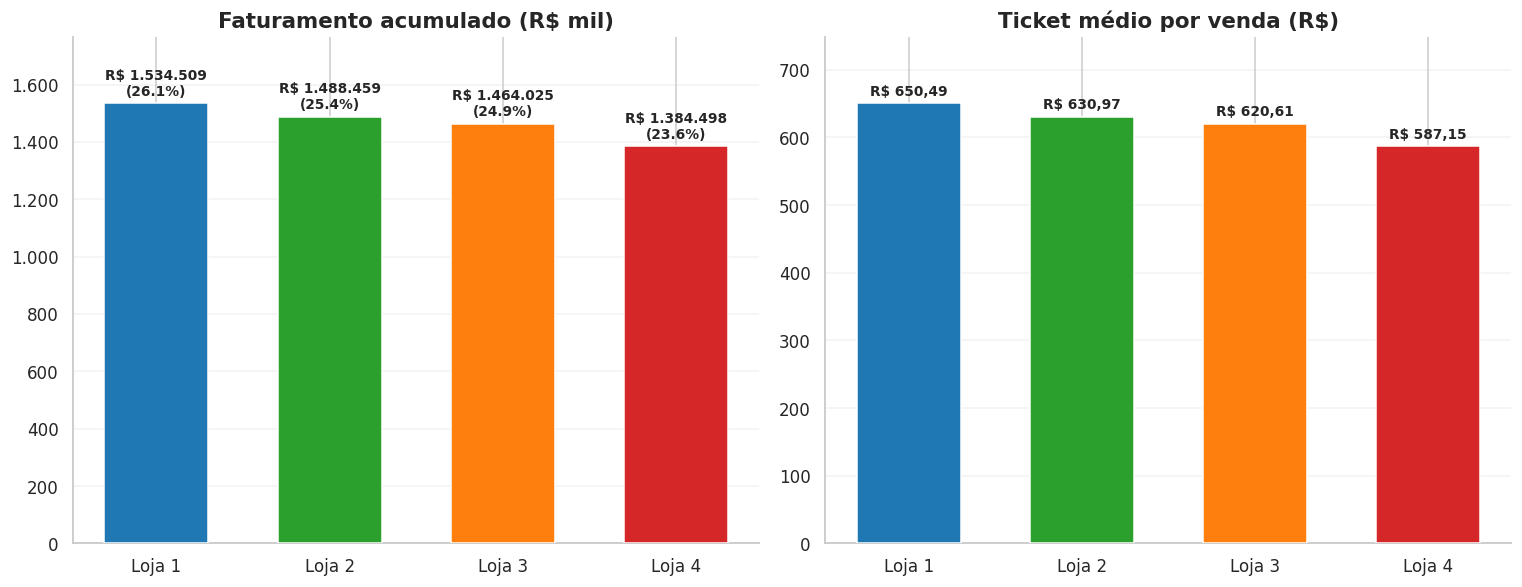

Registros por loja (volume): {'Loja 1': 2359, 'Loja 2': 2359, 'Loja 3': 2359, 'Loja 4': 2358}
Frete/faturamento (mín-máx): 5.33% a 5.33% -> sem poder discriminatório.


In [57]:
# ------------------------------------------------------------
# 4. INDICADORES COMERCIAIS POR LOJA
# ------------------------------------------------------------
ind = dados.groupby("loja").agg(
    faturamento_total=("Preço", "sum"),
    vendas=("Produto", "size"),
    ticket_medio=("Preço", "mean"),
    frete_medio=("Frete", "mean"),
    frete_total=("Frete", "sum"),
    avaliacao_media=("Avaliação da compra", "mean"),
    avaliacoes_baixas=("Avaliação da compra", lambda s: (s <= 2).sum()),
)
ind["participacao_pct"] = ind["faturamento_total"] / ind["faturamento_total"].sum() * 100
ind["avaliacoes_baixas_pct"] = ind["avaliacoes_baixas"] / ind["vendas"] * 100
ind["frete_sobre_fat_pct"] = ind["frete_total"] / ind["faturamento_total"] * 100
ind["receita_media_anual"] = ind["faturamento_total"] / anos_periodo
ind = ind.sort_values("faturamento_total", ascending=False)
display(ind.round(2))

# Gráfico 1: faturamento acumulado e ticket médio
fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5))

barras = eixos[0].bar(ind.index, ind["faturamento_total"],
                      color=[PALETA[l] for l in ind.index], width=0.6, zorder=3)
eixos[0].set_title("Faturamento acumulado (R$ mil)")
eixo_mil(eixos[0])
eixos[0].set_ylim(0, ind["faturamento_total"].max() * 1.15)
for b, (l, r) in zip(barras, ind.iterrows()):
    eixos[0].annotate(f"{brl(r.faturamento_total)}\n({r.participacao_pct:.1f}%)",
                      (b.get_x() + b.get_width() / 2, b.get_height()),
                      xytext=(0, 5), textcoords="offset points",
                      ha="center", fontsize=9, fontweight="bold")

ticket = ind["ticket_medio"].sort_values(ascending=False)
barras = eixos[1].bar(ticket.index, ticket.values,
                      color=[PALETA[l] for l in ticket.index], width=0.6, zorder=3)
eixos[1].set_title("Ticket médio por venda (R$)")
eixos[1].set_ylim(0, ticket.max() * 1.15)
for b, v in zip(barras, ticket.values):
    eixos[1].annotate(brl(v, 2), (b.get_x() + b.get_width() / 2, b.get_height()),
                      xytext=(0, 5), textcoords="offset points",
                      ha="center", fontsize=9, fontweight="bold")
for ax in eixos:
    ax.grid(axis="y", alpha=0.25, zorder=0)
plt.tight_layout()
plt.show()

# Diagnóstico: diferença é de volume ou de preço?
print("Registros por loja (volume):", ind["vendas"].to_dict())
amplitude = ind["frete_sobre_fat_pct"].max() - ind["frete_sobre_fat_pct"].min()
print(f"Frete/faturamento (mín-máx): {ind['frete_sobre_fat_pct'].min():.2f}% a "
      f"{ind['frete_sobre_fat_pct'].max():.2f}% -> "
      + ("sem poder discriminatório." if amplitude < 0.05 else "há variação a investigar."))

loja,Loja 1,Loja 2,Loja 3,Loja 4
Trimestre,,,,
2020Q1,"139,601.26","105,378.42","108,513.54","94,283.75"
2020Q2,"131,394.38","105,553.35","105,240.95","131,115.97"
2020Q3,"128,607.25","104,198.25","114,862.14","115,109.13"
2020Q4,"92,308.62","112,158.23","100,326.46","100,620.67"
2021Q1,"116,693.56","108,139.10","94,524.20","123,312.88"
2021Q2,"108,333.25","111,567.09","111,251.75","103,309.31"
2021Q3,"155,092.98","128,755.27","100,760.54","122,929.83"
2021Q4,"102,710.12","119,827.43","177,402.42","114,211.25"
2022Q1,"105,866.59","116,855.89","119,044.09","130,521.42"


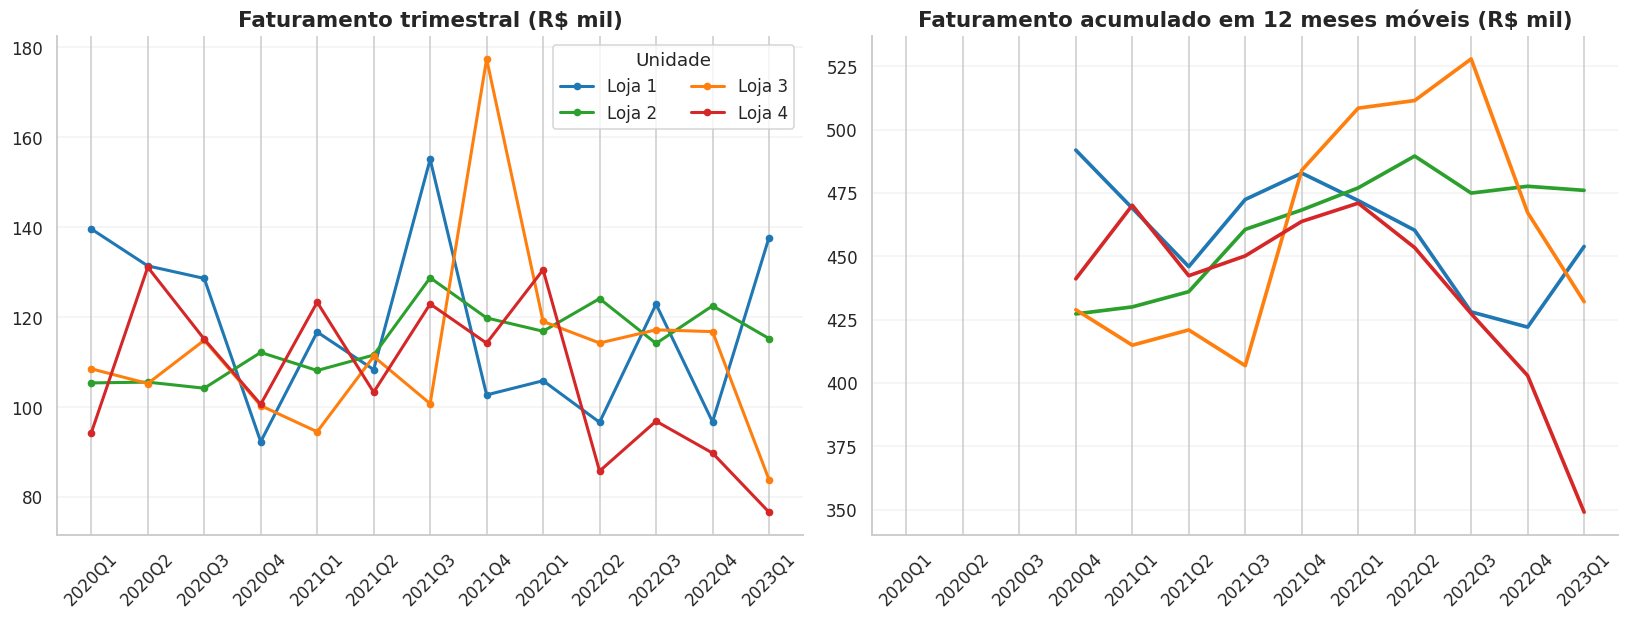

In [58]:
# ------------------------------------------------------------
# 5. TENDÊNCIA: SÉRIE TRIMESTRAL COMPLETA
# ------------------------------------------------------------
ft = (dados.pivot_table(index="Trimestre", columns="loja",
                        values="Preço", aggfunc="sum").sort_index())
display(ft.round(2))

udm_serie = ft.rolling(4).sum()      # últimos 12 meses móveis (elimina sazonalidade)
yoy = ft.pct_change(4) * 100         # variação sobre mesmo trimestre do ano anterior

# Gráfico 2: trimestral e acumulado 12 meses móveis
fig, eixos = plt.subplots(1, 2, figsize=(15, 5.8), sharex=True)
x_labels = ft.index.astype(str)
for loja in LOJAS:
    eixos[0].plot(x_labels, ft[loja], marker="o", ms=4, lw=2, color=PALETA[loja], label=loja)
    eixos[1].plot(x_labels, udm_serie[loja], lw=2.4, color=PALETA[loja], label=loja)
eixos[0].set_title("Faturamento trimestral (R$ mil)")
eixos[1].set_title("Faturamento acumulado em 12 meses móveis (R$ mil)")
for ax in eixos:
    eixo_mil(ax)
    ax.grid(axis="y", alpha=0.25)
    ax.tick_params(axis="x", rotation=45)
eixos[0].legend(ncol=2, title="Unidade")
plt.tight_layout()
plt.show()

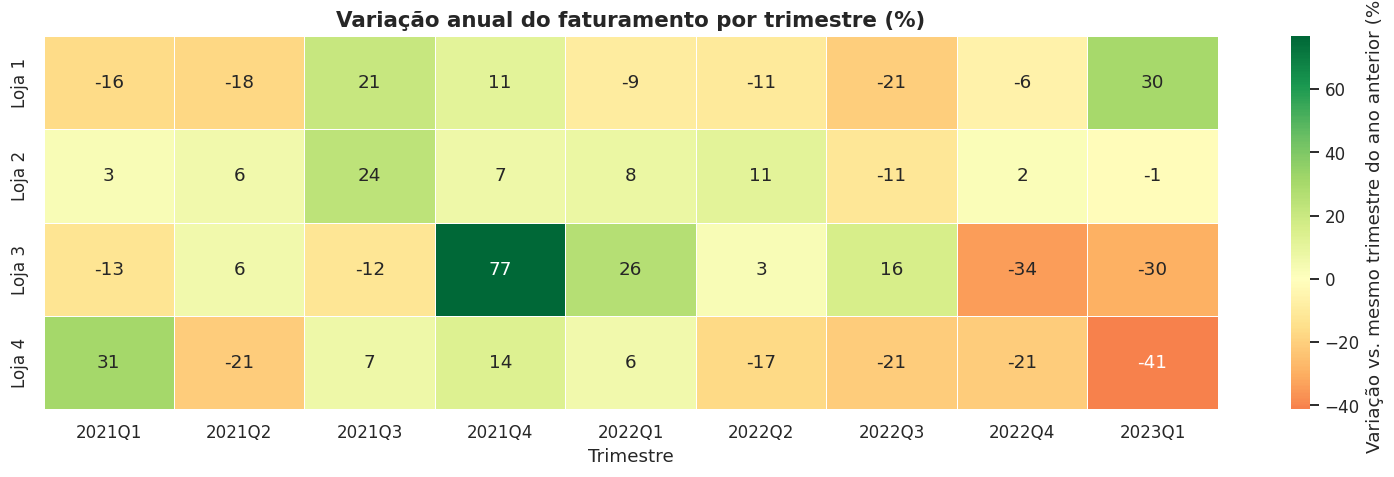

,receita_ant_12m,receita_ult_12m,variacao_12m_pct,variacao_ultimo_tri_vs_ano_ant_pct,inclinacao_R$_por_tri,tendencia_pct_tri,p_valor_tendencia,r2
loja,,,,,,,,
Loja 4,"470,971.81","349,083.37",-25.88,-41.28,"-2,223.24",-2.09,0.09,0.24
Loja 3,"508,458.80","432,098.94",-15.02,-29.53,418.61,0.37,0.81,0.01
Loja 1,"472,002.94","453,901.11",-3.83,30.05,"-1,220.58",-1.03,0.42,0.06
Loja 2,"477,005.68","476,026.03",-0.20,-1.38,"1,348.26",1.18,0.01,0.46


Leitura: p_valor_tendencia < 0,05 indica inclinação distinta de zero; com 13 pontos, o poder do teste é limitado.


In [59]:
# Gráfico 3: heatmap da variação anual por trimestre
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(yoy.dropna().T, cmap="RdYlGn", center=0, annot=True, fmt=".0f",
            linewidths=0.5, cbar_kws={"label": "Variação vs. mesmo trimestre do ano anterior (%)"}, ax=ax)
ax.set_title("Variação anual do faturamento por trimestre (%)")
ax.set_xlabel("Trimestre")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

# Métricas de tendência
ult4, ant4 = ft.tail(4).sum(), ft.iloc[-8:-4].sum()
x = np.arange(len(ft))
linhas = []
for loja in LOJAS:
    r = stats.linregress(x, ft[loja].values)
    linhas.append({
        "loja": loja,
        "receita_ant_12m": ant4[loja],
        "receita_ult_12m": ult4[loja],
        "variacao_12m_pct": (ult4[loja] / ant4[loja] - 1) * 100,
        "variacao_ultimo_tri_vs_ano_ant_pct": yoy[loja].iloc[-1],
        "inclinacao_R$_por_tri": r.slope,
        "tendencia_pct_tri": r.slope / ft[loja].mean() * 100,
        "p_valor_tendencia": r.pvalue,
        "r2": r.rvalue ** 2,
    })
tendencia = pd.DataFrame(linhas).set_index("loja").sort_values("variacao_12m_pct")
display(tendencia.round(3))
print("Leitura: p_valor_tendencia < 0,05 indica inclinação distinta de zero; "
      "com 13 pontos, o poder do teste é limitado.")

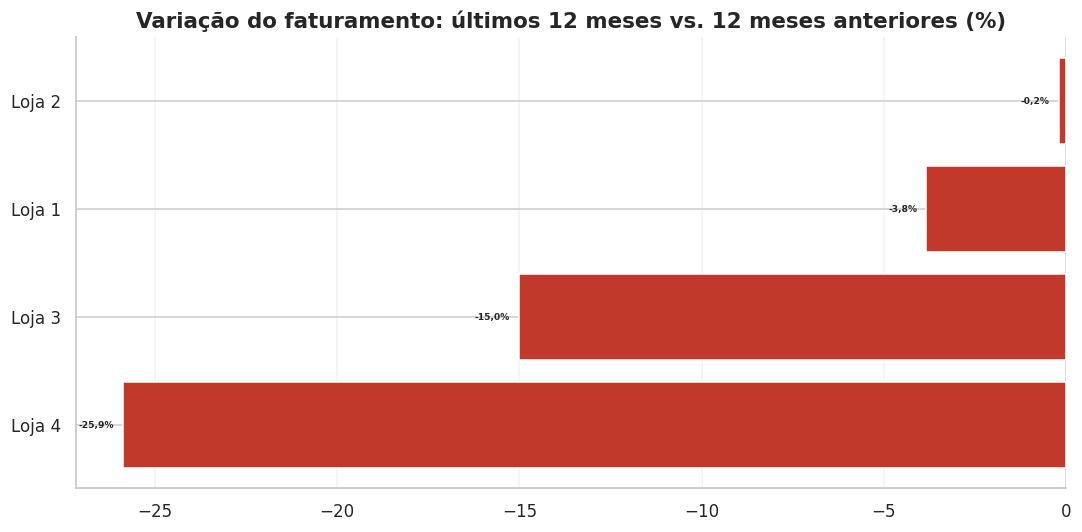

In [77]:
# Gráfico 4: variação em 12 meses
fig, ax = plt.subplots(figsize=(10, 5))
ordem = tendencia["variacao_12m_pct"]
cores = [COR_NEGATIVO if v < 0 else COR_POSITIVO for v in ordem.values]
barras = ax.barh(ordem.index, ordem.values, color=cores, zorder=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Variação do faturamento: últimos 12 meses vs. 12 meses anteriores (%)")
for b, v in zip(barras, ordem.values):
    ax.annotate(f"{v:+.1f}%".replace(".", ","),
                (v, b.get_y() + b.get_height() / 2),
                xytext=(6 if v >= 0 else -6, 0), textcoords="offset points",
                ha="left" if v >= 0 else "right", va="center", fontweight="bold", fontsize=6)
ax.grid(axis="x", alpha=0.25, zorder=0)
plt.tight_layout()
plt.show()

In [61]:
# ------------------------------------------------------------
# 6. ROBUSTEZ ESTATÍSTICA DO TICKET (a diferença é real?)
# ------------------------------------------------------------
grupos = {l: g["Preço"].values for l, g in dados.groupby("loja")}
kw = stats.kruskal(*grupos.values())
print(f"Kruskal-Wallis (Preço entre as 4 lojas): p = {kw.pvalue:.4f}")

pares, pvals = [], []
for i, a in enumerate(LOJAS):
    for b in LOJAS[i + 1:]:
        pares.append((a, b))
        pvals.append(stats.mannwhitneyu(grupos[a], grupos[b]).pvalue)
comparacoes = pd.DataFrame({
    "par": [f"{a} x {b}" for a, b in pares],
    "p_valor": pvals,
    "p_ajustado_holm": holm(pvals),
})
comparacoes["significativo_5pct"] = comparacoes["p_ajustado_holm"] < 0.05
display(comparacoes.round(4))

# IC 95% por bootstrap da diferença de ticket médio (maior vs. menor)
loja_max, loja_min = ind["ticket_medio"].idxmax(), ind["ticket_medio"].idxmin()
def bootstrap_medias(x, n=10_000, lote=1_000):
    """Bootstrap da média em lotes, para não sobrecarregar a memória."""
    medias = np.empty(n)
    for i in range(0, n, lote):
        medias[i:i + lote] = rng.choice(x, (lote, len(x))).mean(axis=1)
    return medias

m_max = bootstrap_medias(grupos[loja_max])
m_min = bootstrap_medias(grupos[loja_min])
dif = m_max - m_min
print(f"Diferença de ticket {loja_max} - {loja_min}: "
      f"{brl(ind.loc[loja_max, 'ticket_medio'] - ind.loc[loja_min, 'ticket_medio'], 2)} "
      f"(IC 95%: {brl(li, 2)} a {brl(ls, 2)})")
print("Se o IC não contém zero, a diferença de ticket é estatisticamente relevante.")


Kruskal-Wallis (Preço entre as 4 lojas): p = 0.0800


,par,p_valor,p_ajustado_holm,significativo_5pct
0,Loja 1 x Loja 2,0.36,1.00,False
1,Loja 1 x Loja 3,0.55,1.00,False
2,Loja 1 x Loja 4,0.01,0.08,False
3,Loja 2 x Loja 3,0.72,1.00,False
4,Loja 2 x Loja 4,0.13,0.50,False
5,Loja 3 x Loja 4,0.05,0.27,False


Diferença de ticket Loja 1 - Loja 4: R$ 63,34 (IC 95%: R$ 19,12 a R$ 109,03)
Se o IC não contém zero, a diferença de ticket é estatisticamente relevante.


In [62]:
# ------------------------------------------------------------
# 7. EXPERIÊNCIA DO CLIENTE
# ------------------------------------------------------------
kw_nota = stats.kruskal(*[g["Avaliação da compra"].values for _, g in dados.groupby("loja")])
tabela_cont = pd.crosstab(dados["loja"], dados["Avaliação da compra"] <= 2)
qui2 = stats.chi2_contingency(tabela_cont)
print(f"Kruskal-Wallis (nota entre lojas): p = {kw_nota.pvalue:.4f}")
print(f"Qui-quadrado (proporção de notas 1-2): p = {qui2[1]:.4f}")
display(ind[["avaliacao_media", "avaliacoes_baixas_pct"]]
        .sort_values("avaliacao_media", ascending=False).round(2))

Kruskal-Wallis (nota entre lojas): p = 0.2282
Qui-quadrado (proporção de notas 1-2): p = 0.4030


,avaliacao_media,avaliacoes_baixas_pct
loja,,
Loja 3,4.05,15.94
Loja 2,4.04,15.52
Loja 4,4.00,16.75
Loja 1,3.98,17.17


Score ponderado (menor = pior desempenho relativo):


,score
loja,
Loja 4,1.15
Loja 3,2.15
Loja 1,3.15
Loja 2,3.55


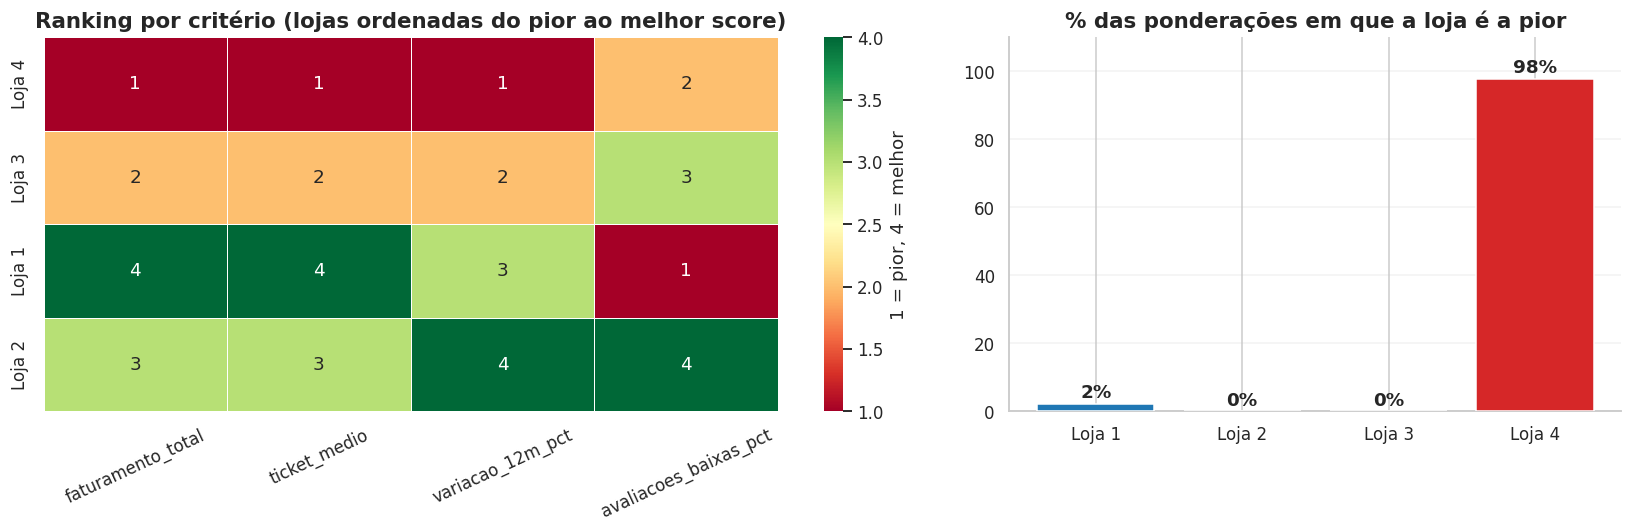

Candidata ao encerramento: Loja 4 (pior em 98% das ponderações simuladas).


In [63]:
# ------------------------------------------------------------
# 8. SCORECARD E TESTE DE SENSIBILIDADE DOS PESOS
# ------------------------------------------------------------
metricas = pd.DataFrame({
    "faturamento_total": ind["faturamento_total"],
    "ticket_medio": ind["ticket_medio"],
    "variacao_12m_pct": tendencia["variacao_12m_pct"],
    "avaliacoes_baixas_pct": ind["avaliacoes_baixas_pct"],
}).loc[LOJAS]

# Ranking: 1 = pior desempenho, 4 = melhor
ranks = metricas.rank(ascending=True)
ranks["avaliacoes_baixas_pct"] = metricas["avaliacoes_baixas_pct"].rank(ascending=False)

pesos = pd.Series(PESOS)
assert abs(pesos.sum() - 1) < 1e-9, "Os pesos devem somar 1."
score = (ranks[pesos.index] * pesos).sum(axis=1).sort_values()
pior_loja = score.index[0]

print("Score ponderado (menor = pior desempenho relativo):")
display(score.round(2).to_frame("score"))

# Sensibilidade: 10.000 conjuntos aleatórios de pesos
W = rng.dirichlet(np.ones(len(pesos)), size=10_000)
scores_sim = ranks[pesos.index].values @ W.T
pior_sim = np.argmin(scores_sim, axis=0)
prob_pior = (pd.Series(pior_sim).map(dict(enumerate(ranks.index)))
             .value_counts(normalize=True).reindex(LOJAS).fillna(0) * 100)

fig, eixos = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(ranks.loc[score.index], annot=True, fmt=".0f", cmap="RdYlGn",
            vmin=1, vmax=4, cbar_kws={"label": "1 = pior, 4 = melhor"},
            linewidths=0.5, ax=eixos[0])
eixos[0].set_title("Ranking por critério (lojas ordenadas do pior ao melhor score)")
eixos[0].set_ylabel("")
eixos[0].tick_params(axis="x", rotation=25)

barras = eixos[1].bar(prob_pior.index, prob_pior.values,
                      color=[PALETA[l] for l in prob_pior.index], zorder=3)
eixos[1].set_title("% das ponderações em que a loja é a pior")
eixos[1].set_ylim(0, 110)
eixos[1].grid(axis="y", alpha=0.25, zorder=0)
for b, v in zip(barras, prob_pior.values):
    eixos[1].annotate(f"{v:.0f}%", (b.get_x() + b.get_width() / 2, b.get_height()),
                      xytext=(0, 4), textcoords="offset points",
                      ha="center", fontweight="bold")
plt.tight_layout()
plt.show()
print(f"Candidata ao encerramento: {pior_loja} "
      f"(pior em {prob_pior[pior_loja]:.0f}% das ponderações simuladas).")


loja,Loja 1,Loja 2,Loja 3,Loja 4
Categoria do Produto,,,,
brinquedos,"23,994.00","21,262.00","25,869.00","27,016.00"
eletrodomesticos,"484,913.00","464,758.00","438,985.00","377,681.00"
eletronicos,"572,659.00","547,774.00","547,700.00","545,967.00"
esporte e lazer,"52,388.00","46,326.00","47,456.00","44,466.00"
instrumentos musicais,"121,732.00","139,987.00","103,174.00","100,136.00"
livros,"11,714.00","13,454.00","12,665.00","12,428.00"
moveis,"250,178.00","235,235.00","268,096.00","256,706.00"
utilidades domesticas,"16,931.00","19,663.00","20,080.00","20,099.00"


loja,Loja 1,Loja 2,Loja 3,Loja 4
Categoria do Produto,,,,
brinquedos,1.56,1.43,1.77,1.95
eletrodomesticos,31.60,31.22,29.98,27.28
eletronicos,37.32,36.80,37.41,39.43
esporte e lazer,3.41,3.11,3.24,3.21
instrumentos musicais,7.93,9.40,7.05,7.23
livros,0.76,0.90,0.87,0.90
moveis,16.30,15.80,18.31,18.54
utilidades domesticas,1.10,1.32,1.37,1.45


Gap de faturamento de Loja 4 vs. média das demais: R$ -111.167
  Efeito volume: R$ -634 | Efeito ticket: R$ -110.533
  Resíduo da decomposição: R$ -0 (interação entre as lojas comparadas)


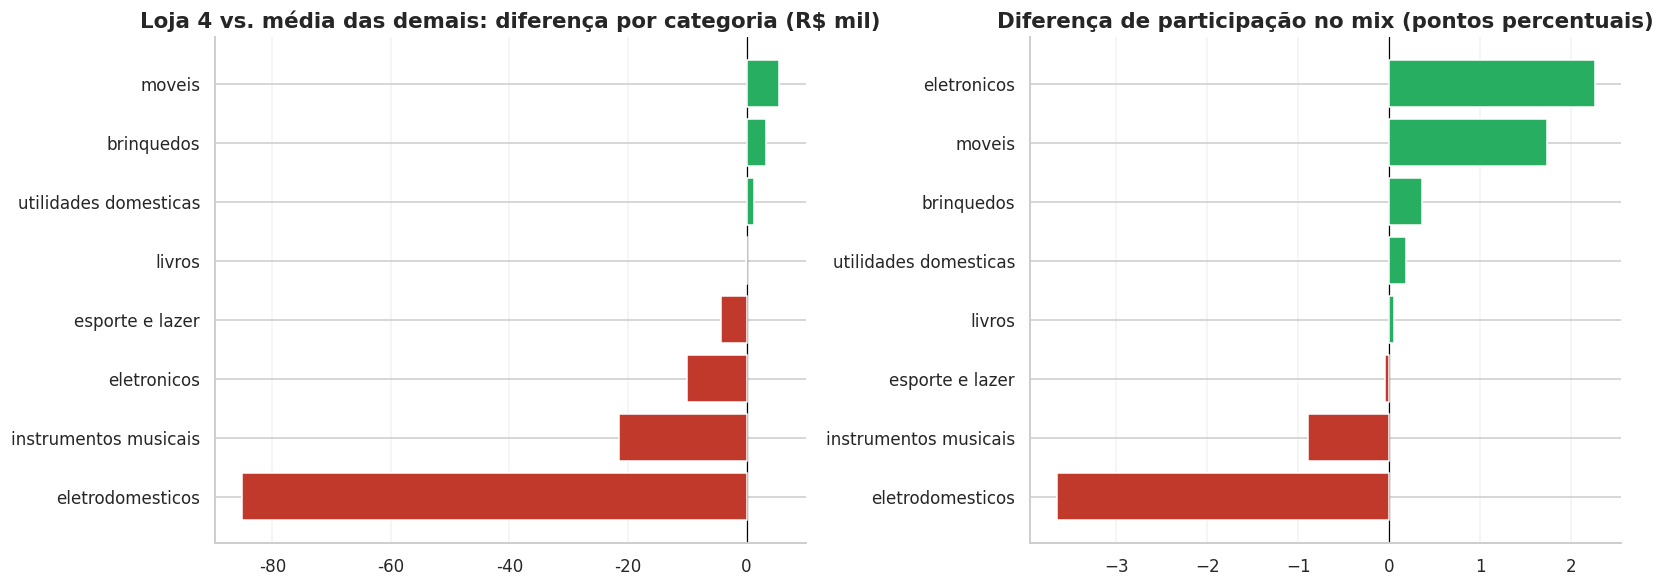

In [64]:
# ------------------------------------------------------------
# 9. DIAGNÓSTICO DO MIX DE CATEGORIAS
# ------------------------------------------------------------
outras = [l for l in LOJAS if l != pior_loja]
tab_cat = dados.pivot_table(index="Categoria do Produto", columns="loja",
                            values="Preço", aggfunc="sum").fillna(0)
mix_pct = tab_cat.div(tab_cat.sum()) * 100
display(tab_cat.round(0))
display(mix_pct.round(2))

gap_cat = (tab_cat[pior_loja] - tab_cat[outras].mean(axis=1)).sort_values()
gap_total = ind.loc[pior_loja, "faturamento_total"] - ind.loc[outras, "faturamento_total"].mean()

# Decomposição: volume x preço
q_p, q_o = ind.loc[pior_loja, "vendas"], ind.loc[outras, "vendas"].mean()
p_p, p_o = ind.loc[pior_loja, "ticket_medio"], ind.loc[outras, "ticket_medio"].mean()
efeito_volume = (q_p - q_o) * p_o
efeito_ticket = q_p * (p_p - p_o)
residuo = gap_total - efeito_volume - efeito_ticket
print(f"Gap de faturamento de {pior_loja} vs. média das demais: {brl(gap_total)}")
print(f"  Efeito volume: {brl(efeito_volume)} | Efeito ticket: {brl(efeito_ticket)}")
print(f"  Resíduo da decomposição: {brl(residuo)} (interação entre as lojas comparadas)")

# Gráfico 5: onde está o gap, por categoria
fig, eixos = plt.subplots(1, 2, figsize=(15, 5.5))
cores = [COR_NEGATIVO if v < 0 else COR_POSITIVO for v in gap_cat.values]
eixos[0].barh(gap_cat.index, gap_cat.values, color=cores, zorder=3)
eixos[0].axvline(0, color="black", lw=0.8)
eixos[0].set_title(f"{pior_loja} vs. média das demais: diferença por categoria (R$ mil)")
eixo_mil(eixos[0], "x")
eixos[0].grid(axis="x", alpha=0.25, zorder=0)

dif_pp = (mix_pct[pior_loja] - mix_pct[outras].mean(axis=1)).sort_values()
cores = [COR_NEGATIVO if v < 0 else COR_POSITIVO for v in dif_pp.values]
eixos[1].barh(dif_pp.index, dif_pp.values, color=cores, zorder=3)
eixos[1].axvline(0, color="black", lw=0.8)
eixos[1].set_title("Diferença de participação no mix (pontos percentuais)")
eixos[1].grid(axis="x", alpha=0.25, zorder=0)
plt.tight_layout()
plt.show()

Receita dos últimos 12 meses de Loja 4: R$ 349.083

Custo fixo anual (R$) a partir do qual o fechamento passa a criar valor:


,retenção 0%,retenção 10%,retenção 20%,retenção 30%
margem 20%,"69,817.00","62,835.00","55,853.00","48,872.00"
margem 30%,"104,725.00","94,253.00","83,780.00","73,308.00"
margem 40%,"139,633.00","125,670.00","111,707.00","97,743.00"


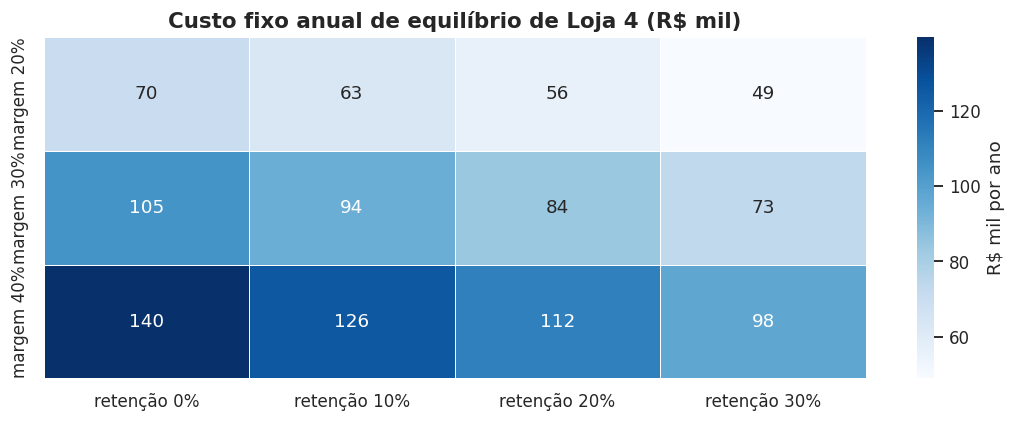

Alternativa ao fechamento: igualar Loja 4 à média das demais nas categorias deficitárias representaria ~R$ 37.331 de receita adicional por ano (teto teórico).


In [65]:
# ------------------------------------------------------------
# 10. VISÃO FINANCEIRA: O FECHAMENTO COMPENSA?
# ------------------------------------------------------------
receita_udm = ult4[pior_loja]
print(f"Receita dos últimos 12 meses de {pior_loja}: {brl(receita_udm)}")

# Custo fixo anual de equilíbrio: acima disso, fechar cria valor
equilibrio = pd.DataFrame(
    {f"retenção {round(r * 100)}%": [receita_udm * m * (1 - r) for m in MARGENS]
     for r in RETENCOES},
    index=[f"margem {round(m * 100)}%" for m in MARGENS],
)
print("\nCusto fixo anual (R$) a partir do qual o fechamento passa a criar valor:")
display(equilibrio.round(0))

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(equilibrio / 1000, annot=True, fmt=",.0f", cmap="Blues", linewidths=0.5,
            cbar_kws={"label": "R$ mil por ano"}, ax=ax)
ax.set_title(f"Custo fixo anual de equilíbrio de {pior_loja} (R$ mil)")
plt.tight_layout()
plt.show()

# Alternativa: reposicionar o mix (fechar o gap nas categorias deficitárias)
deficit_anual = -gap_cat[gap_cat < 0].sum() / anos_periodo
print(f"Alternativa ao fechamento: igualar {pior_loja} à média das demais nas categorias "
      f"deficitárias representaria ~{brl(deficit_anual)} de receita adicional por ano (teto teórico).")